# Impedance to sound: listening to a didgeridoo given by its peaks

Sometimes a didgeridoo is known only by its impedance peaks: a drone and a few toots, each with a
frequency, an impedance and a Q. The peaks may come from a design target ("drone in D, toots on …"), from an
optimizer, or from a recording (see [impedance_from_sound.md](../impedance_from_sound.md),
`estimate_impedance`). This notebook shows the two ways `didgelab.synth` makes such a didgeridoo audible:

* `method="modal"`: a `ModalBore`, a bore built directly from the peaks,
* `method="geometry"`: `fit_geometry` finds a real bore with these peaks, and that bore is played.

It has three parts:

1. **Introduction**: what the two methods do
2. **Maths**: the modal model and the geometry fit
3. **Code examples**: a target, both methods, their spectra and their sound

How the synthesizer turns a bore into sound is explained in
[geometry_to_sound.ipynb](geometry_to_sound.ipynb); the geometry fit in detail in
[geometry_fit.ipynb](geometry_fit.ipynb).

## 1. Introduction

The impedance spectrum of a didgeridoo is a row of peaks. Each peak is one note the instrument can play:
the first is the drone, the higher ones are the toots. A peak has three numbers:

* **frequency**: which note,
* **impedance**: how strong the resonance is (higher = easier to play, louder),
* **Q**: how narrow the peak is (Q = frequency / width of the peak).

To synthesize a sound, the synthesizer needs more than the peaks. It also needs to know how much of the
sound in the mouthpiece reaches the bell, at every frequency. For a real bore this follows from the shape.
For a didgeridoo given only by its peaks there are two options:

* **Modal (`ModalBore`).** Build the impedance spectrum as a sum of simple resonators, one per peak. The
  sound at the bell gets the same resonances, with a strength taken from a rule of thumb that was fitted on
  the didgeridoos of the Didge Archive. This is instant, and the notes are exactly the target notes. The
  timbre is only an estimate: on average it is right, but a single didgeridoo can come out up to about
  twice as bright or half as bright as a real bore with the same peaks.
* **Geometry (`fit_geometry`).** Search for a real bore shape whose peaks match the target, then play that
  bore. This takes a few seconds. The sound is that of a physically possible didgeridoo. The notes are those
  of the fitted bore, usually within a few cents of the target. If no bore fits, the misfit tells you that
  the target is not realistic.

Neither method gives *the* sound of the target. Many different bores share the same first peaks and still
sound different, because the timbre also depends on what happens above and between the peaks.

## 2. Maths

### 2.1 One resonance

A single peak with frequency $f_n$, height $Z_n$ and quality factor $Q_n$ is a second-order resonator:

$$R_n(f) = \frac{1}{1 + jQ_n\left(\dfrac{f}{f_n} - \dfrac{f_n}{f}\right)}, \qquad
|Z_n R_n(f_n)| = Z_n .$$

$|R_n|$ falls to $1/\sqrt2$ (−3 dB) where $Q_n(f/f_n - f_n/f) = \pm 1$. The two solutions are
exactly $f_n/Q_n$ apart, so $Q_n = f_n / \text{bandwidth}$, the same definition DidgeLab uses for its peaks.

### 2.2 Why $Z_{in}$ and $H$ have the same resonances

For a real bore (transmission-line model, see [geometry_to_sound.ipynb](geometry_to_sound.ipynb)) with
chain matrix $\begin{pmatrix}A&B\\C&D\end{pmatrix}$ and radiation impedance $Z_r$:

$$Z_{in} = \frac{A Z_r + B}{C Z_r + D}, \qquad H = \frac{U_{bell}}{U_{mouth}} = \frac{1}{C Z_r + D}.$$

Both have the same denominator. Its zeros (at complex frequencies) are the resonances, so near every
resonance both $Z_{in}$ and $H$ behave like the same resonator $R_n$, each with its own weight (residue).

### 2.3 The modal bore (`ModalBore`)

`ModalBore` writes both spectra as sums over the given peaks:

$$Z_{in}(f) = Z_{bg}(f) + \sum_n Z_n\,R_n(f),
\qquad
H(f) = -j \sum_n g(f_n)\,\frac{Z_n}{Z_0}\,R_n(f).$$

* $Z_0 = \rho c / (\pi d_0^2/4)$ is the characteristic impedance of the mouthpiece (diameter $d_0$,
  `mouth_diameter`).
* $Z_{bg}(f) = Z_0\,\dfrac{(f/4\,\text{kHz})^2}{1 + (f/4\,\text{kHz})^2}$ is a background. It rises
  from 0 to $Z_0$ above about 4 kHz, where the impedance of a real didgeridoo levels out at $Z_0$.
* The residues of $H$ are not known without a geometry. They are set to $g\,Z_n / Z_0$ with $g = 2$: at the
  low peaks of the Didge Archive bores $|H| / (|Z_{in}|/Z_0)$ is about 2. The factor $-j$ fixes the phase of
  all modes. A roll-off of $g$ above 1–3 kHz, alternating signs or a dependence on Q did not match the
  brightness of the real bores better (see the `ModalBore` docstring).

The rest of the synthesizer is unchanged. The filter gain from the lip source to the radiated sound is

$$G(f) = j\frac{f}{100\ \text{Hz}}\; H(f)\;\frac{Z_s}{Z_s + Z_{vt}(f) + Z_{in}(f)}\;
\Big(\frac{f}{1\ \text{kHz}}\Big)^{\kappa/(20\log_{10}2)},$$

and harmonic $n$ of a drone at $f_0$ has the amplitude $P_n = a\,S_n\,G(nf_0)$ (`harmonic_spectrum`).
The drone is played on $f_1$, a toot 34 cents below $f_2$. The envelope time constant of a partial on a
resonance, the group delay of $H$, is

$$\tau = -\frac{d \arg R_n}{d\omega}\Big|_{f = f_n} = \frac{Q_n}{\pi f_n},$$

the same as for a real bore with this Q.

### 2.4 Accuracy of the modal bore

* **Pitch:** exact. The drone and toots are played on the given peak frequencies.
* **Brightness** (spectral centroid of a drone with the mouth of a "doo"): over the Didge Archive and 24
  generated bores 0.85 times that of the real geometry with the same peaks on average, a single bore 0.43 to
  1.6 times (mean deviation 23 %). The peaks below 3 kHz do not carry enough information about the timbre.

In this notebook brightness is measured as the power-weighted mean frequency of the harmonics,
$f_c = \sum_n n f_0 |P_n|^2 \big/ \sum_n |P_n|^2$.

### 2.5 The geometry method (`fit_geometry`)

The bore is piecewise conical: the mouthpiece diameter is fixed, the length and 12 diameters are free. A
least-squares fit minimises, for each target peak, the error in cents and the log ratios of impedance and Q:

$$r_{n} = \Big(\frac{1200\log_2(f_n^{fit}/f_n)}{10},\;\;
0.3\,\frac{\ln(Z_n^{fit}/Z_n)}{\ln 1.25},\;\;
0.3\,\frac{\ln(Q_n^{fit}/Q_n)}{\ln 1.25}\Big).$$

Details (peak extraction, start shapes, stages) are in [geometry_fit.ipynb](geometry_fit.ipynb). The result
is a `GeometryFit`; its sanity check is

$$\texttt{max\_cents} = \max_n \big|1200 \log_2(f_n^{fit}/f_n)\big| ,$$

which is infinite if the fitted bore lacks one of the target peaks. A large value means that the target is
probably not a buildable didgeridoo.

## 3. Code examples

In [1]:
import sys, time
sys.path.insert(0, "../../src")   # use the didgelab of this repository

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from IPython.display import Audio, display

from didgelab import compute_moist_air_properties
from didgelab.synth import (Bore, ModalBore, ModelParams, VOWELS, fit_geometry, harmonic_spectrum,
                            render_song_loop_from_peaks)

constants = compute_moist_air_properties(temp_celsius=28)
params = ModelParams()
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 1.5,
                     "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                          "#e87ba4", "#008300", "#6250d6", "#e34948"])})
db = lambda x: 20 * np.log10(np.abs(x) + 1e-30)

def centroid(P, f0):
    w = np.abs(P) ** 2
    return float(np.sum(w * f0 * np.arange(1, len(P) + 1)) / np.sum(w))

### 3.1 A target

A drone at D2 and three toots. Impedance is in Pa·s/m³, the unit of DidgeLab. Peaks are given as
`(freq, impedance, q)` tuples, dicts or `Resonance` objects.

In [2]:
target = [
    (73.4, 2.0e7, 20),    # D2, drone
    (196.0, 9.0e6, 25),   # G3
    (311.1, 5.0e6, 30),   # D#4
    (440.0, 3.0e6, 35),   # A4
]
MOUTH = 30   # mouthpiece diameter in mm, sets Z_0

modal = ModalBore(target, mouth_diameter=MOUTH, constants=constants)
print(f"Z_0 = {modal.Z0 / 1e6:.2f} MPa s/m³")

Z_0 = 0.57 MPa s/m³


### 3.2 The modal impedance and transfer function

Left: $|Z_{in}|$ of the `ModalBore` (sum of the resonators plus background), the single resonators
(dashed) and the target points. Right: $|H|$, with the same peaks.

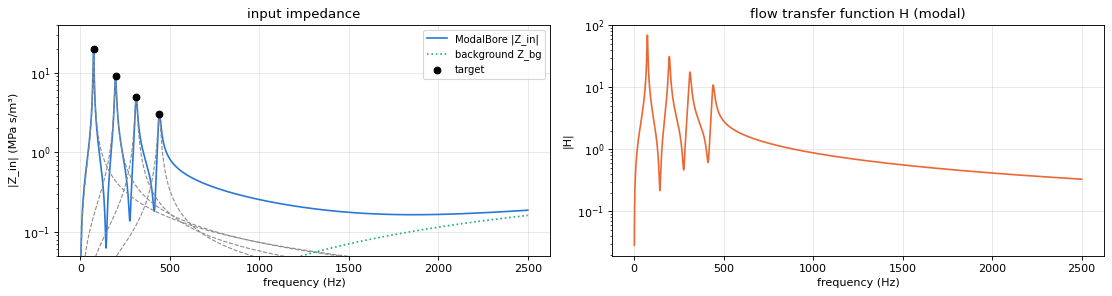

target Hz   modal max Hz   target MPa   modal max MPa
     73.4           73.5        20.00           19.96
    196.0          196.0         9.00            9.02
    311.1          311.5         5.00            5.08
    440.0          441.0         3.00            3.14


In [3]:
f = modal.freqs
m = f <= 2500
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 3.8))
a1.plot(f[m], np.abs(modal.Zin[m]) / 1e6, color="C0", label="ModalBore |Z_in|")
for r in modal.resonances:
    a1.plot(f[m], np.abs(r.impedance / (1 + 1j * r.q * (f[m] / r.freq - r.freq / f[m]))) / 1e6,
            "--", lw=1, color="0.55")
zbg = modal.Z0 * (f / modal.BG_CORNER) ** 2 / (1 + (f / modal.BG_CORNER) ** 2)
a1.plot(f[m], zbg[m] / 1e6, ":", color="C2", label="background Z_bg")
a1.plot([t[0] for t in target], [t[1] / 1e6 for t in target], "o", color="k", label="target")
a1.set(xlabel="frequency (Hz)", ylabel="|Z_in| (MPa s/m³)", yscale="log", ylim=(0.05, 40), title="input impedance")
a1.legend(fontsize=9)
a2.plot(f[m], np.abs(modal.H[m]), color="C1")
a2.set(xlabel="frequency (Hz)", ylabel="|H|", yscale="log", title="flow transfer function H (modal)")
plt.tight_layout(); plt.show()

# the sum of overlapping resonators shifts the maxima slightly
z = np.abs(modal.Zin)
idx, _ = find_peaks(z)
print("target Hz   modal max Hz   target MPa   modal max MPa")
for (ft, zt, q), i in zip(target, idx):
    print(f"{ft:9.1f} {f[i]:14.1f} {zt / 1e6:12.2f} {z[i] / 1e6:15.2f}")

The maxima of the sum are within 1 Hz (4 cents) of the targets and up to 5 % higher, because the tails of
the neighbouring resonators and the background add to each peak. The synthesizer plays the
given frequencies, not the maxima of the sum.

### 3.3 The geometry method

`fit_geometry` searches a bore with the same peaks (details in [geometry_fit.ipynb](geometry_fit.ipynb)).

In [4]:
t = time.time()
fit = fit_geometry(target, mouth_diameter=MOUTH, constants=constants)
print(f"fit took {time.time() - t:.1f} s, {fit.nfev} simulations")
print(f"{'target Hz':>10} {'fitted Hz':>10} {'cents':>7} {'Z ratio':>8} {'Q ratio':>8}")
for tg, p, c, zr, qr in zip(fit.targets, fit.peaks, fit.cents, fit.impedance_ratio, fit.q_ratio):
    print(f"{tg.freq:10.1f} {p.freq:10.1f} {c:7.1f} {zr:8.2f} {qr:8.2f}")
print(f"max_cents = {fit.max_cents:.2f}")
print("geometry:", [[round(x), round(d, 1)] for x, d in fit.geometry])
geo_bore = Bore(fit.geometry, constants=constants)

fit took 1.2 s, 1360 simulations
 target Hz  fitted Hz   cents  Z ratio  Q ratio
      73.4       73.3    -1.5     1.34     2.32
     196.0      195.9    -1.2     2.07     2.80
     311.1      311.4     1.5     2.49     2.79
     440.0      440.3     1.3     2.35     2.62
max_cents = 1.49
geometry: [[0, 30.0], [113, 31.4], [227, 29.7], [340, 30.9], [453, 34.9], [567, 35.5], [680, 35.2], [793, 34.8], [906, 39.1], [1020, 36.2], [1133, 41.9], [1246, 44.1], [1360, 41.7]]


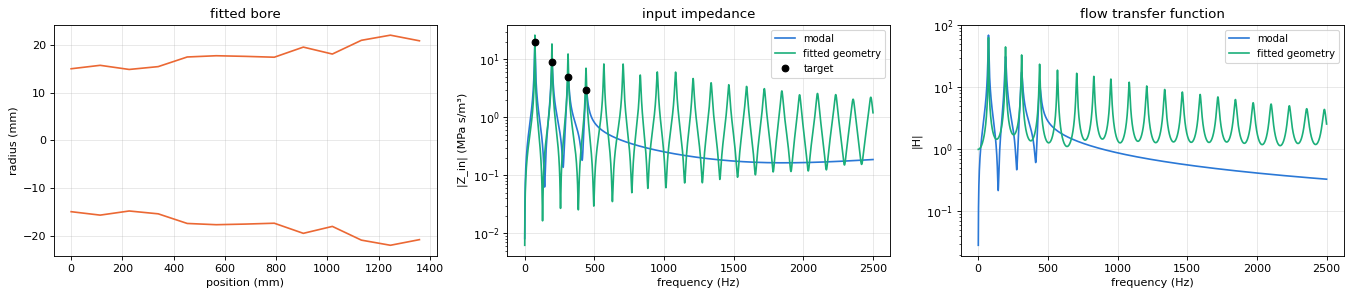

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.8))
g = np.array(fit.geometry)
axs[0].plot(g[:, 0], g[:, 1] / 2, color="C1"); axs[0].plot(g[:, 0], -g[:, 1] / 2, color="C1")
axs[0].set(xlabel="position (mm)", ylabel="radius (mm)", title="fitted bore")
fm = geo_bore.freqs
mm = fm <= 2500
for k, (name, b) in enumerate([("modal", modal), ("fitted geometry", geo_bore)]):
    axs[1].plot(fm[mm], np.abs(b.Zin[mm]) / 1e6, color=f"C{2 * k}" if k else "C0", label=name)
    axs[2].plot(fm[mm], np.abs(b.H[mm]), color=f"C{2 * k}" if k else "C0", label=name)
axs[1].plot([t[0] for t in target], [t[1] / 1e6 for t in target], "o", color="k", label="target")
axs[1].set(xlabel="frequency (Hz)", ylabel="|Z_in| (MPa s/m³)", yscale="log", title="input impedance")
axs[2].set(xlabel="frequency (Hz)", ylabel="|H|", yscale="log", title="flow transfer function")
axs[1].legend(fontsize=9); axs[2].legend(fontsize=9)
plt.tight_layout(); plt.show()

Up to the last target peak (440 Hz) both impedance curves agree closely. Above it they differ: the modal
bore has no more peaks (only the background), the fitted bore has its own higher resonances. $|H|$
differs more, also between the peaks. This is where the two methods give a different timbre.

### 3.4 Harmonic spectra: modal vs. geometry

The steady drone spectrum $P_n = S_n G(nf_0)$ of both bores, for the relaxed neutral mouth and for "ee"
(tongue front). Levels are relative to the strongest harmonic of the fitted geometry.

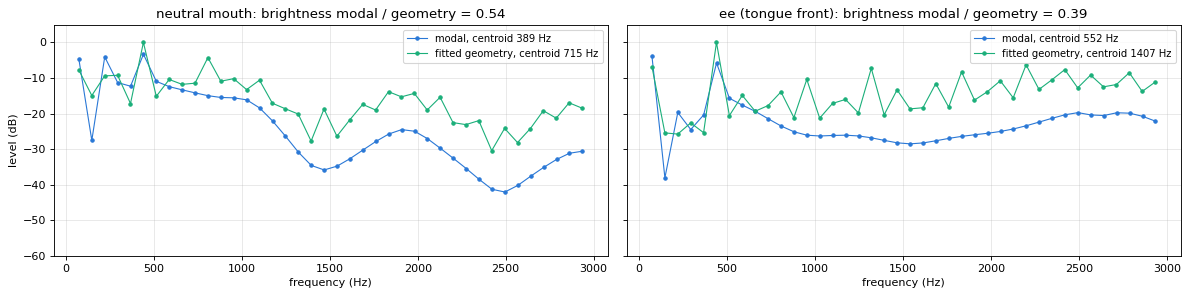

In [6]:
N = 40
fig, axs = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, (vname, vt) in zip(axs, [("neutral mouth", VOWELS["neutral"]), ("ee (tongue front)", VOWELS["i"])]):
    P = {name: harmonic_spectrum(b, b.drone, vt, params, n_harm=N) for name, b in
         [("modal", modal), ("fitted geometry", geo_bore)]}
    ref = np.max(np.abs(P["fitted geometry"]))
    for k, (name, b) in enumerate([("modal", modal), ("fitted geometry", geo_bore)]):
        ax.plot(np.arange(1, N + 1) * b.drone, db(P[name] / ref), "o-", ms=3, lw=1,
                color="C2" if k else "C0", label=f"{name}, centroid {centroid(P[name], b.drone):.0f} Hz")
    ratio = centroid(P["modal"], modal.drone) / centroid(P["fitted geometry"], geo_bore.drone)
    ax.set(xlabel="frequency (Hz)", title=f"{vname}: brightness modal / geometry = {ratio:.2f}", ylim=(-60, 5))
    ax.legend(fontsize=9)
axs[0].set_ylabel("level (dB)")
plt.tight_layout(); plt.show()

The pitch is the same, and harmonic 6 (440 Hz), which falls on the fourth peak, is strong in both. Between
the peaks and above them the two spectra differ by up to 15–20 dB, and the fitted geometry has more ripple
(its own higher resonances). For this target the modal bore is darker than the fitted geometry, within the
0.43–1.6 spread documented for `ModalBore`. The centroid is dominated by the strongest harmonics, here the
fundamental, so it is only a rough measure of brightness. Which one is "right" cannot be decided from the peaks alone;
the fitted geometry is at least one physically possible didgeridoo.

### 3.5 Listening

`render_song_loop_from_peaks` renders a song from `SONGS` for a bore given by its peaks, as a seamless loop.
The same target with both methods:

In [7]:
for method in ("modal", "geometry"):
    t = time.time()
    y, fs = render_song_loop_from_peaks(target, "tiki-du", mouth_diameter=MOUTH, temperature=28,
                                        tempo=90, fs=16000, method=method)
    print(f"method={method!r}: {len(y) / fs:.2f} s of audio, rendered in {time.time() - t:.1f} s")
    display(Audio(y, rate=fs))

method='modal': 2.67 s of audio, rendered in 3.6 s


method='geometry': 2.67 s of audio, rendered in 4.7 s


With `method="geometry"` the fit runs again inside `render_song_loop_from_peaks`; to inspect the bore or
`max_cents`, call `fit_geometry` yourself (as in §3.3) and render `Bore(fit.geometry)` with the synthesizer.

### 3.6 Sanity check: is the target buildable?

A toot at 1.5 times the drone (a fifth above it) is far below the second resonance of any simple
didgeridoo. The modal method plays it anyway. The geometry fit cannot find a bore with this peak: the
second target is missing (`nan`) and `max_cents` is infinite. A rule of thumb: if `max_cents` is more than
about 10 cents, the target is probably not realistic, and the modal sound should not be trusted either.

In [8]:
odd = [(73.4, 2.0e7, 20), (110.0, 9.0e6, 25)]
fit_odd = fit_geometry(odd, mouth_diameter=MOUTH, constants=constants)
print("cents:", np.round(fit_odd.cents, 1), " max_cents:", fit_odd.max_cents)
print("first peaks of the fitted bore:", [round(p.freq, 1) for p in
      Bore(fit_odd.geometry, constants=constants).resonances[:3]])

cents: [-0.1  nan]  max_cents: inf
first peaks of the fitted bore: [73.4, 193.6, 324.6]


**Where the peaks can come from.** A design target as above, the resonances of an existing bore
(`Bore(geo).resonances`), or a recording: `estimate_impedance(x, fs).peaks` returns the peaks of a bore
fitted to a sound sample, see [impedance_from_sound.md](../impedance_from_sound.md). Only the first one or
two peaks of such an estimate are reliable.